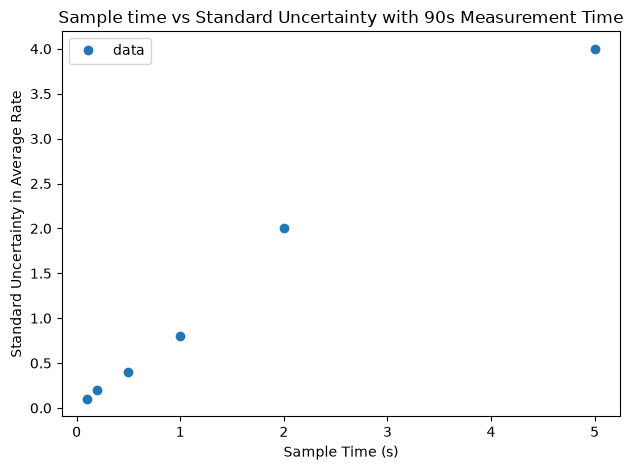

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
def linear(x, a, b):
    return a*x + b

x = np.array([0.1,0.2,0.5,1,2,5])
y = np.array([0.1,0.2,0.4,0.8,2,4])

xx = np.linspace(x.min(), x.max(), 300)
plt.errorbar(x, y, fmt='o', capsize=3, label="data")
plt.xlabel("Sample Time (s)") #TODO
plt.ylabel("Standard Uncertainty in Average Rate") #TODO
plt.title("Sample time vs Standard Uncertainty with 90s Measurement Time") #TODO
plt.legend()
plt.tight_layout()
plt.show()


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Enter each measurement as [x, xerr, y, yerr]; uncertainties are independent 1-sigma values.
raw_data = [   # x is distance in mm; y is rate in N/s
    [10, 5, 126, 1],
    [30, 5, 24.3, 0.3],
    [50, 5, 11.8, 0.3],
    [70, 5, 6.4, 0.2],
    [20, 5, 41.8, 0.7],
    [90, 5, 4.7, 0.2] 
    ]
sample_time = 5  # time in seconds

raw_array = np.asarray(raw_data, dtype=object)
if raw_array.ndim != 2 or raw_array.shape[1] != 4:
    raise ValueError("Each raw_data row must contain exactly [x, xerr, y, yerr].")

missing_xerr_rows = [
    row_number
    for row_number, value in enumerate(raw_array[:, 1], start=1)
    if value is None or value == ""
]
missing_yerr_rows = [
    row_number
    for row_number, value in enumerate(raw_array[:, 3], start=1)
    if value is None or value == ""
]
if missing_xerr_rows or missing_yerr_rows:
    raise ValueError(
        "Enter measured xerr and yerr for every raw_data row. "
        f"Missing xerr on rows: {missing_xerr_rows}; "
        f"missing yerr on rows: {missing_yerr_rows}"
    )

raw_array = raw_array.astype(float)
if not np.all(np.isfinite(raw_array)):
    raise ValueError("All x, xerr, y, and yerr values must be finite numbers.")
if np.any(raw_array[:, 1] < 0) or np.any(raw_array[:, 3] < 0):
    raise ValueError("The xerr and yerr values must be non-negative.")

x_raw = raw_array[:, 0]
x_uncertainty_raw = raw_array[:, 1]
y_raw = raw_array[:, 2]
y_uncertainty_raw = raw_array[:, 3]

# Group repeated x values and calculate uncertainties for their averages.
x_values = np.unique(x_raw)
if len(x_values) < 2:
    raise ValueError("At least two distinct x values are needed to propagate x uncertainty into y.")
summary_rows = []

for x_value in x_values:
    group_mask = x_raw == x_value
    y_same_x = y_raw[group_mask]
    x_uncertainties_same_x = x_uncertainty_raw[group_mask]
    y_uncertainties_same_x = y_uncertainty_raw[group_mask]
    n = len(y_same_x)
    mean_y = np.mean(y_same_x)
    sample_stdev = np.std(y_same_x, ddof=1) if n > 1 else np.nan
    scatter_mean_uncertainty = sample_stdev / np.sqrt(n) if n > 1 else np.nan
    propagated_mean_uncertainty = np.sqrt(np.sum(y_uncertainties_same_x**2)) / n
    mean_x_uncertainty = np.sqrt(np.sum(x_uncertainties_same_x**2)) / n

    if np.isfinite(scatter_mean_uncertainty):
        y_uncertainty_only = max(scatter_mean_uncertainty, propagated_mean_uncertainty)
        uncertainty_source = (
            "scatter" if scatter_mean_uncertainty > propagated_mean_uncertainty
            else "propagated" if propagated_mean_uncertainty > scatter_mean_uncertainty
            else "tie"
        )
    else:
        y_uncertainty_only = propagated_mean_uncertainty
        uncertainty_source = "propagated (one measurement)"

    summary_rows.append({
        "x": x_value,
        "x_err": mean_x_uncertainty,
        "n": n,
        "y_ave": mean_y,
        "y_stdev": sample_stdev,
        "scatter_mean_uncertainty": scatter_mean_uncertainty,
        "propagated_mean_uncertainty": propagated_mean_uncertainty,
        "y_err_y_only": y_uncertainty_only,
        "uncertainty_source": uncertainty_source,
    })

results = pd.DataFrame(summary_rows)
# Estimate local slope from measured averages; x uncertainty does not enter fit weights.
local_slope = np.gradient(results["y_ave"].to_numpy(), results["x"].to_numpy())
results["slope_dy_dx"] = local_slope
results["x_contribution_to_y_uncertainty"] = np.abs(local_slope) * results["x_err"]
results["y_err"] = np.hypot(
    results["y_err_y_only"], results["x_contribution_to_y_uncertainty"]
)

if np.any(results["y_err_y_only"].to_numpy() <= 0):
    zero_uncertainty_x = results.loc[results["y_err_y_only"] <= 0, "x"].tolist()
    raise ValueError(
        "The y-only uncertainty is zero for x="
        f"{zero_uncertainty_x}. Check the supplied y uncertainties."
    )

x_values = results["x"].to_numpy(dtype=float)
x_err = results["x_err"].to_numpy(dtype=float)
y_ave = results["y_ave"].to_numpy(dtype=float)
# Fits keep their original y-only weights; graphs show the combined y uncertainty.
y_err_y_only = results["y_err_y_only"].to_numpy(dtype=float)
y_err = results["y_err"].to_numpy(dtype=float)

print("x values:", x_values)
print("Average y:", y_ave)
print("Combined x uncertainty:", x_err)
print("Sample standard deviation of y:", results["y_stdev"].to_numpy())
print("Y-only uncertainty of average y (fit weights):", y_err_y_only)
print("Combined y uncertainty (including propagated x uncertainty):", y_err)
print("Uncertainty summary:")
print(results)

raw_df = pd.DataFrame(raw_array, columns=["x", "xerr", "y", "yerr"])
print("Raw data:")
print(raw_df)


x values: [10. 20. 30. 50. 70. 90.]
Average y: [126.   41.8  24.3  11.8   6.4   4.7]
Combined x uncertainty: [5. 5. 5. 5. 5. 5.]
Sample standard deviation of y: [nan nan nan nan nan nan]
Y-only uncertainty of average y (fit weights): [1.  0.7 0.3 0.3 0.2 0.2]
Combined y uncertainty (including propagated x uncertainty): [42.11187481 25.43463436  6.88154234  2.25752215  0.90975615  0.46970736]
Uncertainty summary:
      x  x_err  n  y_ave  y_stdev  scatter_mean_uncertainty  \
0  10.0    5.0  1  126.0      NaN                       NaN   
1  20.0    5.0  1   41.8      NaN                       NaN   
2  30.0    5.0  1   24.3      NaN                       NaN   
3  50.0    5.0  1   11.8      NaN                       NaN   
4  70.0    5.0  1    6.4      NaN                       NaN   
5  90.0    5.0  1    4.7      NaN                       NaN   

   propagated_mean_uncertainty  y_err_y_only            uncertainty_source  \
0                          1.0           1.0  propagated (one me

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def add_noise(y_true, frac_noise=0.05, seed=None):
    """
    Add simple Gaussian noise to y_true.
    Noise scale = frac_noise * (max(y_true) - min(y_true)) (falls back to 1 if flat).
    Returns:
        y    : noisy data
        yerr : per-point (constant) noise estimate
    """
    rng = np.random.default_rng(seed)  # reproducible randomness if seed is set
    span = np.ptp(y_true) if y_true.size > 0 else 1.0  # handle flat signals
    sigma = frac_noise * span
    y = y_true + rng.normal(0.0, sigma, size=y_true.size)
    yerr = np.full_like(y_true, sigma, dtype=float)  # assign constant uncertainty at each point
    return y, yerr

a = -0.481426 ± 0.005,  b = 43.4 ± 0.35


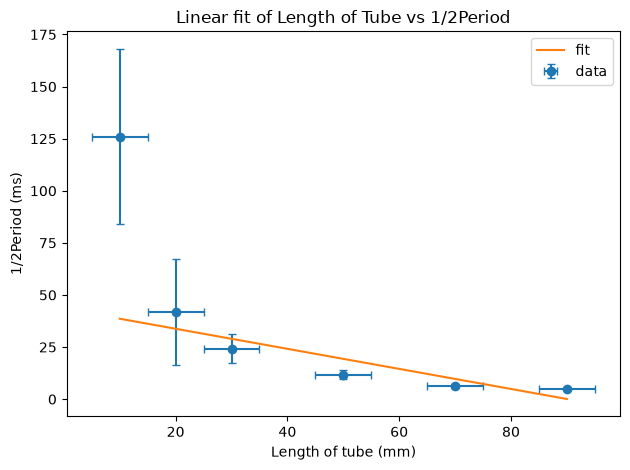

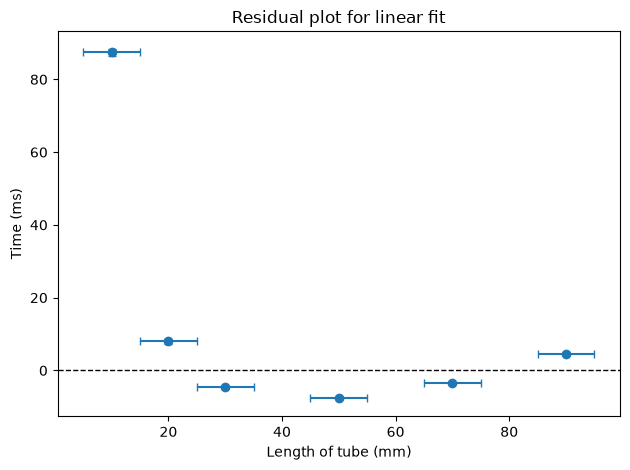

In [18]:
def linear(x, a, b):
    return a*x + b

x = x_values
y = y_ave
yerr = y_err_y_only
yerr_plot = y_err

popt, pcov = curve_fit(linear, x, y, sigma=yerr, absolute_sigma=True)
perr = np.sqrt(np.diag(pcov))
linear_a, linear_b = popt
linear_sa, linear_sb = perr
print(f"a = {linear_a:9g} ± {linear_sa:.2g},  b = {linear_b:.3g} ± {linear_sb:.2g}")

xx = np.linspace(x.min(), x.max(), 300)
plt.errorbar(x, y, xerr=x_err, yerr=yerr_plot, fmt='o', capsize=3, label="data")
plt.plot(xx, linear(xx, linear_a, linear_b), label="fit")
plt.xlabel("Length of tube (mm)") #TODO
plt.ylabel("1/2Period (ms)") #TODO
plt.title("Linear fit of Length of Tube vs 1/2Period") #TODO
plt.legend()
plt.tight_layout()
plt.show()

model_fit = linear(x, linear_a, linear_b)
residuals = y - model_fit

plt.figure()
plt.errorbar(x, residuals, xerr=x_err, yerr=yerr, fmt='o', capsize=3, label="Residuals")
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xlabel("Length of tube (mm)") #TODO
plt.ylabel("Time (ms)") #TODO
plt.title("Residual plot for linear fit")  #TODO
plt.tight_layout()
plt.show()

A = 302 ± 4.8,  tau = 10.5 ± 0.11,  C = 6.04 ± 0.14


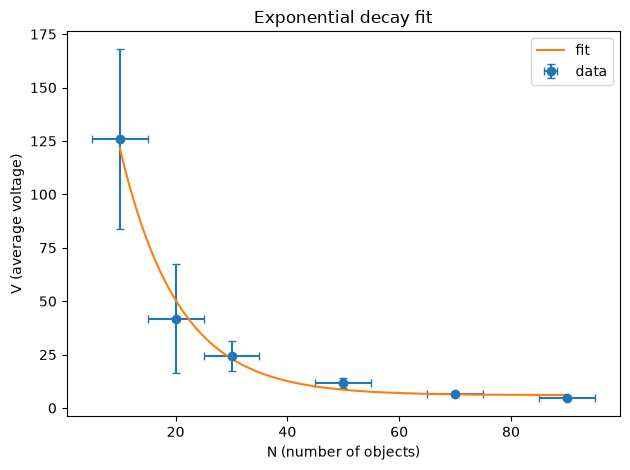

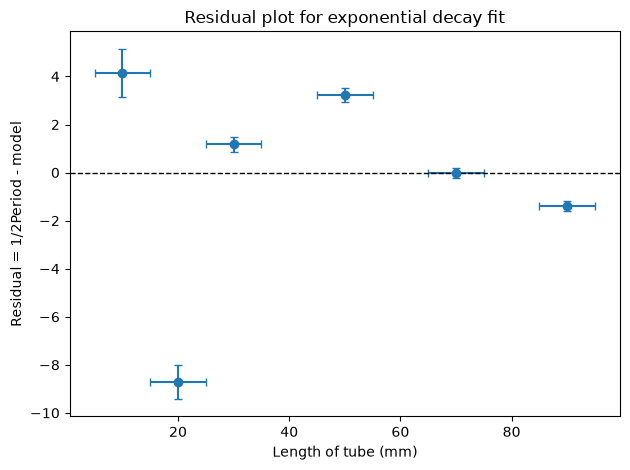

In [19]:
def exp_decay(x, A, tau, C):
    return A * np.exp(-x/tau) + C

# Use the averaged x and y data from the first cell
x = x_values
y = y_ave
yerr = y_err_y_only
yerr_plot = y_err
p0 = (1.0, 1, 0.0)  # initial guess for A, tau, C
# Parameters: A = amplitude, tau = decay constant (same units as x), C = baseline
bounds = ((-np.inf, 0, -np.inf), (np.inf, np.inf, np.inf))  # enforce tau > 0
popt, pcov = curve_fit(exp_decay, x, y, p0=p0, bounds=bounds, sigma=yerr, absolute_sigma=True, maxfev=10000)
perr = np.sqrt(np.diag(pcov))
exp_A, exp_tau, exp_C = popt
exp_sA, exp_stau, exp_sC = perr
print(f"A = {exp_A:.3g} ± {exp_sA:.2g},  tau = {exp_tau:.3g} ± {exp_stau:.2g},  C = {exp_C:.3g} ± {exp_sC:.2g}")

xx = np.linspace(x.min(), x.max(), 300)
plt.errorbar(x, y, xerr=x_err, yerr=yerr_plot, fmt='o', capsize=3, label="data")
plt.plot(xx, exp_decay(xx, exp_A, exp_tau, exp_C), label="fit")
plt.xlabel("N (number of objects)") #TODO
plt.ylabel("V (average voltage)") #TODO
plt.title ("Exponential decay fit") #TODO
plt.legend()
plt.tight_layout()
plt.show()

# ---------- Residual plot ----------
# Input: model function, x values, measured y values, and uncertainty in y
model_fit = exp_decay(x, exp_A, exp_tau, exp_C)
residuals = y - model_fit

plt.figure()
plt.errorbar(x, residuals, xerr=x_err, yerr=yerr, fmt='o', capsize=3, label="Residuals")
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xlabel("Length of tube (mm)") #TODO
plt.ylabel("Residual = 1/2Period - model") #TODO
plt.title("Residual plot for exponential decay fit")  #TODO
plt.tight_layout()
plt.show()

A = 4e+03 ± 1.1e+02,  n = -1.5 ± 0.0092


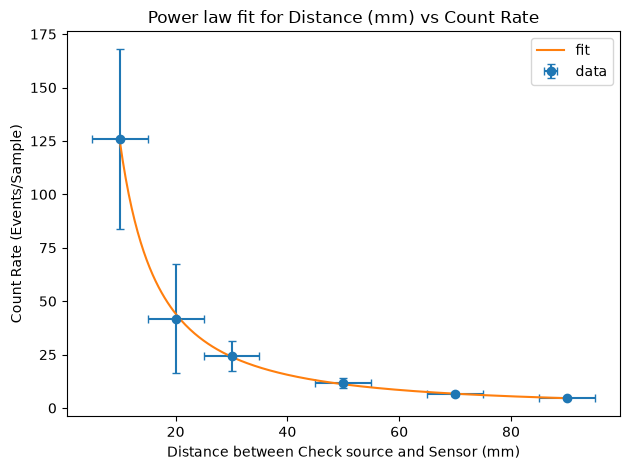

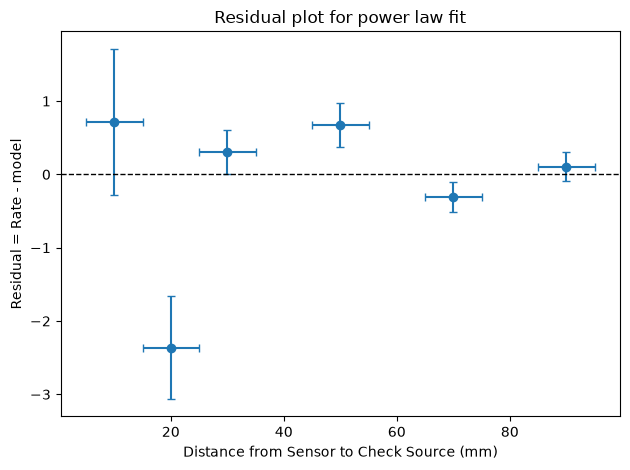

In [20]:
def power_law(x, A, n):
    return A * x**n

# Use the averaged N and V data from the first cell
x = x_values
y = y_ave
yerr = y_err_y_only
yerr_plot = y_err

# Parameters: A = scale factor, n = exponent (often inspected on log–log plots)
p0 = (1.0, 1.0)
popt, pcov = curve_fit(power_law, x, y, p0=p0, sigma=yerr, absolute_sigma=True, maxfev=10000)
perr = np.sqrt(np.diag(pcov))
pow_A, pow_n = popt
pow_sA, pow_sn = perr
print(f"A = {pow_A:.3g} ± {pow_sA:.2g},  n = {pow_n:.3g} ± {pow_sn:.2g}")

xx = np.linspace(x.min(), x.max(), 300)
plt.errorbar(x, y, xerr=x_err, yerr=yerr_plot, fmt='o', capsize=3, label="data")
plt.plot(xx, power_law(xx, pow_A, pow_n), label="fit")
plt.xlabel("Distance between Check source and Sensor (mm)") #TODO
plt.ylabel("Count Rate (Events/Sample)") #TODO
plt.title("Power law fit for Distance (mm) vs Count Rate") #TODO
plt.legend()
plt.tight_layout()
plt.show()

# ---------- Residual plot ----------
# Input: model function, x values, measured y values, and uncertainty in y
model_fit = power_law(x, pow_A, pow_n)
residuals = y - model_fit

plt.figure()
plt.errorbar(x, residuals, xerr=x_err, yerr=yerr, fmt='o', capsize=3, label="Residuals")
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xlabel("Distance from Sensor to Check Source (mm)") #TODO
plt.ylabel("Residual = Rate - model") #TODO
plt.title("Residual plot for power law fit") #TODO
plt.tight_layout()
plt.show()

a = 0.0163 ± 0.00024,  b = -2.39 ± 0.028,  c = 90.1 ± 0.77


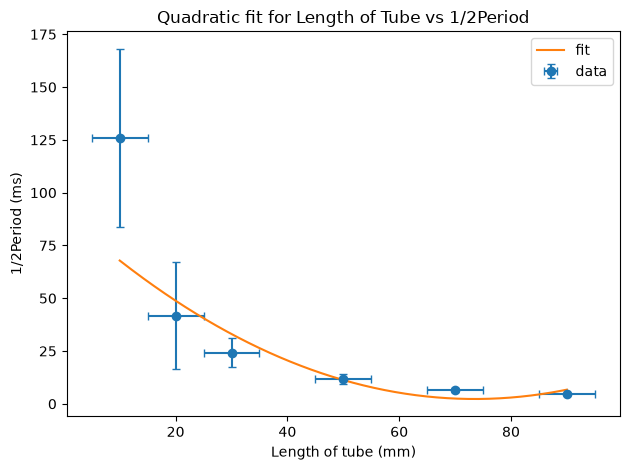

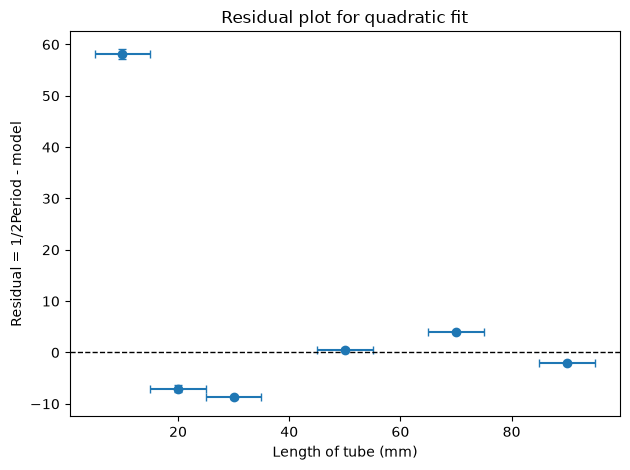

In [21]:
def quad(x, a, b, c):
    return a*x**2 + b*x + c

# Use the averaged N and V data from the first cell
x = x_values
y = y_ave
yerr = y_err_y_only
yerr_plot = y_err

# Parameters: a = curvature, b = linear term, c = intercept
popt, pcov = curve_fit(quad, x, y, sigma=yerr, absolute_sigma=True)
perr = np.sqrt(np.diag(pcov))
quad_a, quad_b, quad_c = popt
quad_sa, quad_sb, quad_sc = perr
print(f"a = {quad_a:.3g} ± {quad_sa:.2g},  b = {quad_b:.3g} ± {quad_sb:.2g},  c = {quad_c:.3g} ± {quad_sc:.2g}")

xx = np.linspace(x.min(), x.max(), 300)
plt.errorbar(x, y, xerr=x_err, yerr=yerr_plot, fmt='o', capsize=3, label="data")
plt.plot(xx, quad(xx, quad_a, quad_b, quad_c), label="fit")
plt.xlabel("Length of tube (mm)") #TODO
plt.ylabel("1/2Period (ms)")#TODO
plt.title("Quadratic fit for Length of Tube vs 1/2Period") #TODO
plt.legend()
plt.tight_layout()
plt.show()

# ---------- Residual plot ----------
# Input: model function, x values, measured y values, and uncertainty in y
model_fit = quad(x, quad_a, quad_b, quad_c)
residuals = y - model_fit

plt.figure()
plt.errorbar(x, residuals, xerr=x_err, yerr=yerr, fmt='o', capsize=3, label="Residuals")
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xlabel("Length of tube (mm)") #TODO
plt.ylabel("Residual = 1/2Period - model") #TODO
plt.title("Residual plot for quadratic fit") #TODO
plt.tight_layout()
plt.show()

c:\UW\Anaconda\Lib\site-packages\scipy\optimize\_lsq\common.py:115: RuntimeWarning: divide by zero encountered in divide
  phi_prime = -np.sum(suf ** 2 / denom**3) / p_norm


A = 5.19e+55 ± 1.1e-53,  mu = -2.58e+03 ± 27,  sigma = 165 ± 1.7,  C = 6.06 ± 0.14


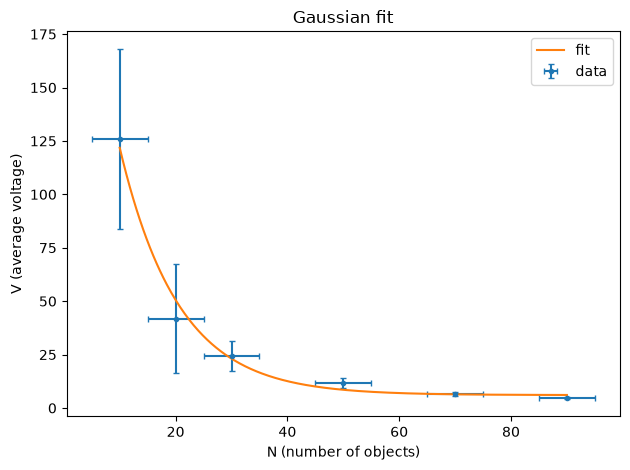

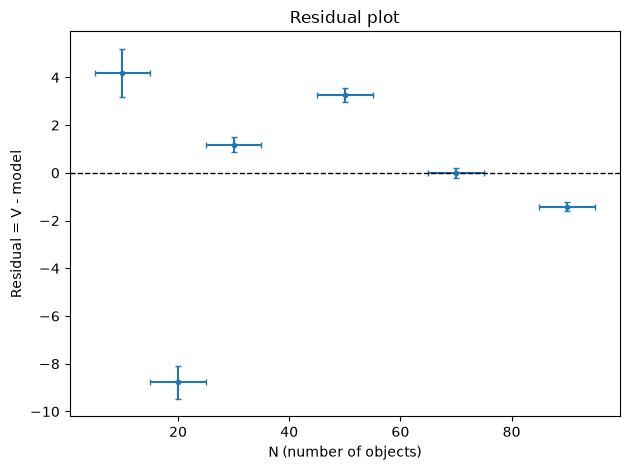

In [22]:
def gaussian(x, A, mu, sigma, C):
    return A * np.exp(-(x - mu)**2 / (2*sigma**2)) + C

# Use the averaged N and V data from the first cell
x = x_values
y = y_ave
yerr = y_err_y_only
yerr_plot = y_err

# Parameters: A = peak height, mu = center, sigma = width, C = background level
bounds = ((-np.inf, -np.inf, 1e-6, -np.inf), (np.inf, np.inf, np.inf, np.inf))  # enforce sigma > 0
popt, pcov = curve_fit(gaussian, x, y, bounds=bounds, sigma=yerr, absolute_sigma=True, maxfev=10000)
perr = np.sqrt(np.diag(pcov))
gauss_A, gauss_mu, gauss_sigma, gauss_C = popt
gauss_sA, gauss_smu, gauss_ssigma, gauss_sC = perr
print(f"A = {gauss_A:.3g} ± {gauss_sA:.2g},  mu = {gauss_mu:.3g} ± {gauss_smu:.2g},  sigma = {gauss_sigma:.3g} ± {gauss_ssigma:.2g},  C = {gauss_C:.3g} ± {gauss_sC:.2g}")

xx = np.linspace(x.min(), x.max(), 400)
plt.errorbar(x, y, xerr=x_err, yerr=yerr_plot, fmt='o', capsize=2, ms=3, label="data")
plt.plot(xx, gaussian(xx, gauss_A, gauss_mu, gauss_sigma, gauss_C), label="fit")
plt.xlabel("N (number of objects)")#TODO
plt.ylabel("V (average voltage)") #TODO
plt.title("Gaussian fit") #TODO
plt.legend()
plt.tight_layout()
plt.show()

# ---------- Residual plot ----------
# Input: model function, x values, measured y values, and uncertainty in y
model_fit = gaussian(x, gauss_A, gauss_mu, gauss_sigma, gauss_C)
residuals = y - model_fit

plt.figure()
plt.errorbar(x, residuals, xerr=x_err, yerr=yerr, fmt='o', capsize=2, ms=3, label="Residuals")
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xlabel("N (number of objects)") #TODO
plt.ylabel("Residual = V - model") #TODO
plt.title("Residual plot") #TODO
plt.tight_layout()
plt.show()

In [23]:
# Predict a new value for x using each fitted model, including uncertainty

x_new = 20

linear_pred = linear_a * x_new + linear_b
linear_pred_err = np.sqrt((x_new * linear_sa)**2 + (linear_sb)**2)
print(f"Linear prediction at x = {x_new}: y = {linear_pred:.3g} ± {linear_pred_err:.3g}")

exp_pred = exp_A * np.exp(-x_new / exp_tau) + exp_C
exp_pred_err = np.sqrt(
    (np.exp(-x_new / exp_tau) * exp_sA)**2 +
    ((exp_A * np.exp(-x_new / exp_tau) * x_new / (exp_tau**2)) * exp_stau)**2 +
    (exp_sC)**2
)
print(f"Exponential prediction at x = {x_new}: y = {exp_pred:.3g} ± {exp_pred_err:.3g}")

power_pred = pow_A * x_new**pow_n
power_pred_err = np.sqrt(
    ((x_new**pow_n) * pow_sA)**2 +
    ((pow_A * x_new**pow_n * np.log(x_new)) * pow_sn)**2
)
print(f"Power-law prediction at x = {x_new}: y = {power_pred:.3g} ± {power_pred_err:.3g}")

quad_pred = quad_a * x_new**2 + quad_b * x_new + quad_c
quad_pred_err = np.sqrt((x_new**2 * quad_sa)**2 + ((x_new) * quad_sb)**2 + (quad_sc)**2)
print(f"Quadratic prediction at x = {x_new}: y = {quad_pred:.3g} ± {quad_pred_err:.3g}")

gauss_pred = gauss_A * np.exp(-((x_new - gauss_mu)**2) / (2*gauss_sigma**2)) + gauss_C
gauss_factor = np.exp(-((x_new - gauss_mu)**2) / (2*gauss_sigma**2))
gauss_pred_err = np.sqrt(
    (gauss_factor * gauss_sA)**2 +
    ((gauss_A * gauss_factor * (x_new - gauss_mu) / (gauss_sigma**2)) * gauss_smu)**2 +
    ((gauss_A * gauss_factor * ((x_new - gauss_mu)**2 / (gauss_sigma**3))) * gauss_ssigma)**2 +
    (gauss_sC)**2
)
print(f"Gaussian prediction at x = {x_new}: y = {gauss_pred:.3g} ± {gauss_pred_err:.3g}")

Linear prediction at x = 20: y = 33.8 ± 0.364
Exponential prediction at x = 20: y = 50.5 ± 1.14
Power-law prediction at x = 20: y = 44.2 ± 1.69
Quadratic prediction at x = 20: y = 48.8 ± 0.963
Gaussian prediction at x = 20: y = 50.6 ± 164


In [24]:
def rmse(y_true, y_pred): #Reduced Mean Square Error
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# Compute RMSE for each fitted model
models = {}

models["linear"] = rmse(y, linear(x, linear_a, linear_b))
models["exponential"] = rmse(y, exp_decay(x, exp_A, exp_tau, exp_C))
models["power_law"] = rmse(y, power_law(x, pow_A, pow_n))
models["quadratic"] = rmse(y, quad(x, quad_a, quad_b, quad_c))
models["gaussian"] = rmse(y, gaussian(x, gauss_A, gauss_mu, gauss_sigma, gauss_C))

for name, value in models.items():
    print(f"{name:>11}: RMSE = {value:.6f}")

best_model = min(models, key=models.get)
print(f"\nBest fit by RMSE: {best_model} ({models[best_model]:.6f})")

     linear: RMSE = 36.085066
exponential: RMSE = 4.224827
  power_law: RMSE = 1.060063
  quadratic: RMSE = 24.244176
   gaussian: RMSE = 4.255631

Best fit by RMSE: power_law (1.060063)
